In [15]:
import pandas as pd
import numpy as np

# Carga tu CSV
df = pd.read_csv("Master_Neoantigenos_Filogenia_Pairtree_FIXED.csv", low_memory=False)

# --- Función de clasificación ---
def classify_tree(group):
    group = group  # incluye grouping columns fix
    n_unique_ccf = group['CCF'].nunique()
    n_unique_clonality = group['clonality'].nunique()
    all_clonal = (group['clonality'] == 'Clonal').all()
    ccf_range = group['CCF'].max() - group['CCF'].min()

    if all_clonal or n_unique_ccf == 1 or ccf_range < 0.05:
        tree_type = 'TRIVIAL (1 nodo)'
    elif n_unique_ccf == 2 or n_unique_clonality == 2:
        tree_type = 'SIMPLE (2 clusters)'
    else:
        tree_type = 'COMPLEJO (>=3 clusters)'

    return pd.Series({
        'n_mutations': len(group),
        'n_unique_CCF': n_unique_ccf,
        'CCF_range': round(ccf_range, 3),
        'all_clonal': all_clonal,
        'n_clonal': (group['clonality'] == 'Clonal').sum(),
        'n_subclonal': (group['clonality'] == 'Subclonal').sum(),
        'tree_type': tree_type
    })

# --- Aplica por paciente ---
summary = df.groupby('patient', group_keys=False).apply(classify_tree).reset_index()

# --- Resultados ---
print(summary['tree_type'].value_counts())
print(summary)

tree_type
COMPLEJO (>=3 clusters)    80
TRIVIAL (1 nodo)           47
SIMPLE (2 clusters)         5
Name: count, dtype: int64
      patient  n_mutations  n_unique_CCF  CCF_range  all_clonal  n_clonal  \
0    DO221541        14665             0        NaN       False         0   
1    DO221544        14102             0        NaN       False         0   
2    DO224575          250             1        0.0       False         0   
3    DO224656         9333             0        NaN       False         0   
4    DO224712        12860             0        NaN       False         0   
..        ...          ...           ...        ...         ...       ...   
127   DO51532        10151             0        NaN       False         0   
128   DO51537         7627             0        NaN       False         0   
129   DO51542         8131             0        NaN       False         0   
130   DO51543        11730             0        NaN       False         0   
131   DO51548        10748 

/tmp/ipykernel_3088/1602064358.py:33: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = df.groupby('patient', group_keys=False).apply(classify_tree).reset_index()


In [16]:
# Diagnóstico rápido
print("=== NaN en CCF ===")
print(df['CCF'].isna().sum(), "de", len(df), "filas")

print("\n=== NaN en clonality ===")
print(df['clonality'].isna().sum(), "de", len(df), "filas")

print("\n=== Valores únicos de clonality ===")
print(df['clonality'].value_counts(dropna=False))

print("\n=== Muestra de CCF ===")
print(df['CCF'].describe())

print("\n=== Nombres exactos de columnas ===")
print(df.columns.tolist())

=== NaN en CCF ===
1219453 de 1282383 filas

=== NaN en clonality ===
0 de 1282383 filas

=== Valores únicos de clonality ===
clonality
Unknown      1219453
Subclonal      56628
Clonal          6302
Name: count, dtype: int64

=== Muestra de CCF ===
count    62930.000000
mean         0.201326
std          0.351699
min          0.000000
25%          0.000767
50%          0.001222
75%          0.334502
max          1.000000
Name: CCF, dtype: float64

=== Nombres exactos de columnas ===
['patient', 'chromosome', 'genomic_coord', 'ref', 'alt', 'gene', 'transcript', 'protein_coord', 'aa_mutant', 'aa_wt', 'mut_seq', 'wt_seq', 'mutant_seq', 'consequence', 'parent_seq', 'mutant_best_alleles', 'mutant_best_allele_PRIME', 'mutant_best_alleles_netMHCpan', 'mutant_rank', 'mutant_rank_netMHCpan', 'mutant_rank_PRIME', 'mut_Rank_Stab', 'mut_netchop_score_ct', 'mut_binding_score', 'mut_is_binding_pos', 'DAI_NetMHC', 'DAI_MixMHC', 'DAI_NetStab', 'nb_same_mutation_Intogen', 'mutation_driver_statement_Int

In [17]:
# Filtra solo mutaciones asignadas
df_assigned = df[df['clonality'] != 'Unknown'].copy()

print(f"Mutaciones asignadas: {len(df_assigned)} de {len(df)} ({100*len(df_assigned)/len(df):.1f}%)")
print(f"Pacientes con al menos 1 mutación asignada: {df_assigned['patient'].nunique()} de {df['patient'].nunique()}")

# Re-clasifica solo con mutaciones asignadas
summary = df_assigned.groupby('patient', group_keys=False).apply(classify_tree).reset_index()
print(summary['tree_type'].value_counts())
print(summary[['patient','n_mutations','n_unique_CCF','CCF_range','tree_type']])

Mutaciones asignadas: 62930 de 1282383 (4.9%)
Pacientes con al menos 1 mutación asignada: 54 de 132
tree_type
TRIVIAL (1 nodo)           47
SIMPLE (2 clusters)         6
COMPLEJO (>=3 clusters)     1
Name: count, dtype: int64
     patient  n_mutations  n_unique_CCF  CCF_range                tree_type
0   DO224575          250             1      0.000         TRIVIAL (1 nodo)
1   DO224714         1561             1      0.000         TRIVIAL (1 nodo)
2   DO224724         2005             1      0.000         TRIVIAL (1 nodo)
3   DO224734           50             1      0.000         TRIVIAL (1 nodo)
4   DO224740           50             1      0.000         TRIVIAL (1 nodo)
5   DO224745         1349             1      0.000         TRIVIAL (1 nodo)
6   DO224764           50             1      0.000         TRIVIAL (1 nodo)
7   DO224767          100             1      0.000         TRIVIAL (1 nodo)
8   DO224779           50             1      0.000         TRIVIAL (1 nodo)
9   DO224784  

/tmp/ipykernel_3088/51487734.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = df_assigned.groupby('patient', group_keys=False).apply(classify_tree).reset_index()


In [18]:
# ¿Cuántos valores únicos de CCF hay realmente?
print(df_assigned['CCF'].value_counts().head(20))

# ¿Cuántos clusters por paciente?
print(df_assigned.groupby('patient')['CCF'].nunique().value_counts())

CCF
0.001383    5913
0.000432    3855
0.785143    3584
0.000964    2907
1.000000    2805
0.000529    2419
0.000844    2120
0.001953    2053
0.000893    2005
0.334502    1865
1.000000    1847
0.435551    1725
0.000716    1709
0.000460    1700
0.001343    1561
0.000842    1554
0.000654    1535
0.000767    1525
0.000505    1385
0.000868    1362
Name: count, dtype: int64
CCF
1    47
2     4
3     3
Name: count, dtype: int64


Clonal: 12,228
Subclonal: 43,168
✅ Guardado Figura_B_Immunogenicity.png (con fondo blanco mate y ejes negros)


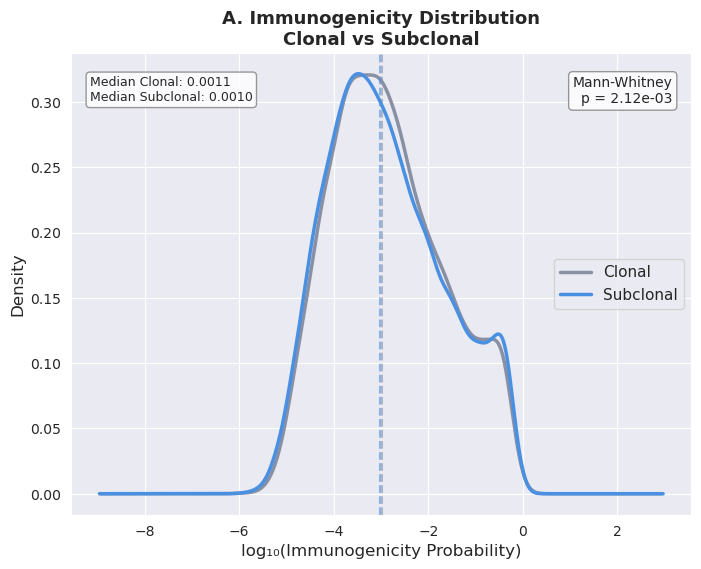

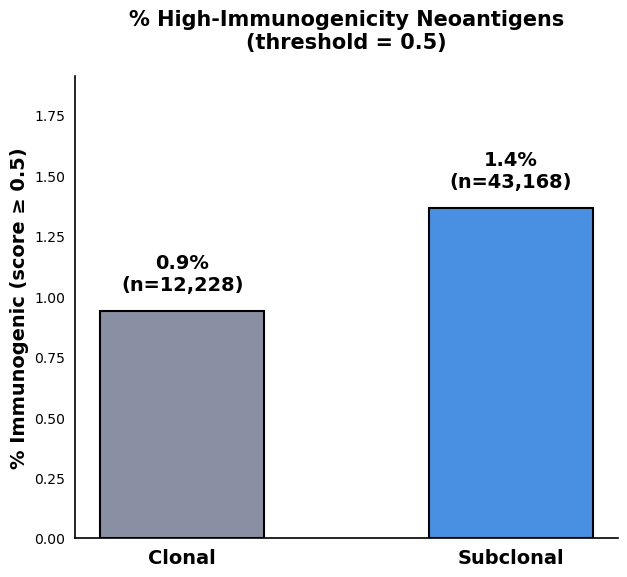

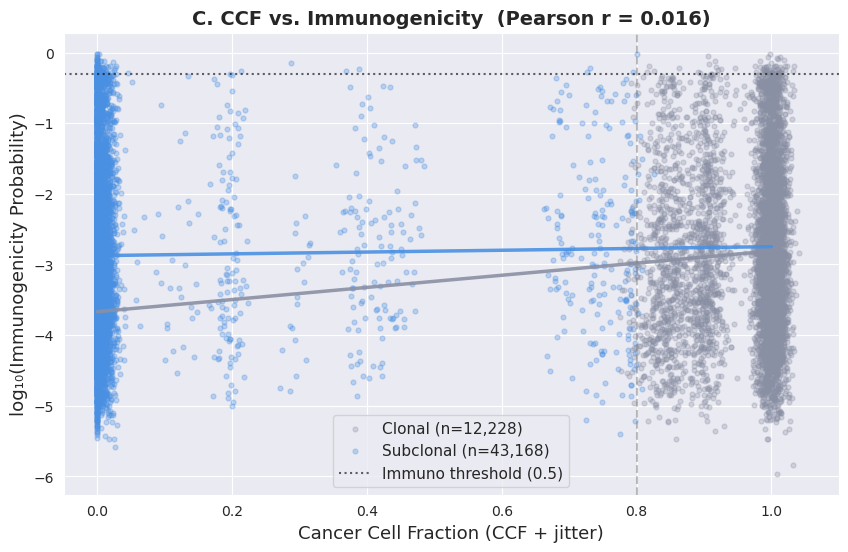

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

# ==============================================================
# CARGAR Y PREPARAR
# ==============================================================
df_final = pd.read_csv("Master_Neoantigenos_Filogenia_PhyClone.csv", low_memory=False)
df_preds = pd.read_csv("Full_Dataset_Predictions.csv", low_memory=False)
df_preds = df_preds.rename(columns={'Peptide': 'mut_seq'}) if 'Peptide' in df_preds.columns else df_preds

df_plot = pd.merge(
    df_preds[['patient','mut_seq','Immunogenicity_Probability']],
    df_final[['patient','mut_seq','CCF','clonality']].drop_duplicates(subset=['patient','mut_seq']),
    on=['patient','mut_seq'], how='inner'
)
df_plot['clonality'] = df_plot['clonality'].astype(str).str.capitalize().str.strip()
df_plot = df_plot[df_plot['clonality'].isin(['Clonal','Subclonal'])].copy()
df_plot = df_plot.dropna(subset=['Immunogenicity_Probability','CCF'])

print(f"Clonal: {(df_plot['clonality']=='Clonal').sum():,}")
print(f"Subclonal: {(df_plot['clonality']=='Subclonal').sum():,}")

# COLORES BASADOS EN TU FIGURA 10D
colors  = {'Clonal': '#8A90A4', 'Subclonal': '#4A90E2'}
THRESH  = 0.5   # umbral inmunogenicidad alta

# ==============================================================
# FIGURA A: Distribución KDE
# ==============================================================
fig_a, ax_a = plt.subplots(figsize=(8, 6))

for label, grp in df_plot.groupby('clonality'):
    vals = np.log10(grp['Immunogenicity_Probability'].clip(lower=1e-6))
    vals.plot.kde(ax=ax_a, color=colors[label], linewidth=2.5, label=label)
    ax_a.axvline(vals.median(), color=colors[label], linestyle='--', alpha=0.6, linewidth=1.5)

ax_a.set_xlabel("log₁₀(Immunogenicity Probability)", fontsize=12)
ax_a.set_ylabel("Density", fontsize=12)
ax_a.set_title("A. Immunogenicity Distribution\nClonal vs Subclonal", fontsize=13, fontweight='bold')
ax_a.legend(fontsize=11)

# Stats
c_vals = df_plot[df_plot['clonality']=='Clonal']['Immunogenicity_Probability']
s_vals = df_plot[df_plot['clonality']=='Subclonal']['Immunogenicity_Probability']
stat, p_val = mannwhitneyu(c_vals, s_vals, alternative='two-sided')
p_text = f"p = {p_val:.2e}" if p_val > 1e-300 else "p < 1e-300"
ax_a.text(0.97, 0.95, f"Mann-Whitney\n{p_text}",
          transform=ax_a.transAxes, ha='right', va='top',
          fontsize=10, bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray'))

# Mediana de cada grupo
med_c = c_vals.median()
med_s = s_vals.median()
ax_a.text(0.03, 0.95,
          f"Median Clonal: {med_c:.4f}\nMedian Subclonal: {med_s:.4f}",
          transform=ax_a.transAxes, ha='left', va='top',
          fontsize=9, bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray'))

# ==============================================================
# FIGURA B: % neoantígenos inmunogénicos (barplot)
# ==============================================================
fig_b, ax_b = plt.subplots(figsize=(7, 6))

# Forzar explícitamente el fondo blanco para la figura y los ejes
fig_b.patch.set_facecolor('white')
ax_b.set_facecolor('white')

df_plot['is_immunogenic'] = df_plot['Immunogenicity_Probability'] >= THRESH
pct = df_plot.groupby('clonality')['is_immunogenic'].mean() * 100
n_per_group = df_plot.groupby('clonality').size()

bars = ax_b.bar(pct.index, pct.values,
                color=[colors[x] for x in pct.index],
                edgecolor='black', linewidth=1.5, width=0.5)

# Calculamos un espacio dinámico proporcional
espacio_texto = max(pct.values) * 0.05 

for bar, val, n in zip(bars, pct.values, [n_per_group.get('Clonal',0), n_per_group.get('Subclonal',0)]):
    ax_b.text(bar.get_x() + bar.get_width()/2, bar.get_height() + espacio_texto,
              f"{val:.1f}%\n(n={n:,})", ha='center', va='bottom',
              fontsize=14, fontweight='bold', color='black')

# Textos
ax_b.set_ylabel(f"% Immunogenic (score ≥ {THRESH})", fontsize=14, fontweight='bold', color='black')
ax_b.set_xticks(range(len(pct.index)))
ax_b.set_xticklabels(pct.index, fontsize=14, fontweight='bold', color='black')
ax_b.set_title(f"% High-Immunogenicity Neoantigens\n(threshold = {THRESH})",
               fontsize=15, fontweight='bold', pad=20, color='black')

# -------------------------------------------------------------
# CONTROL EXPLICITO DE LOS EJES (Líneas Negras)
# -------------------------------------------------------------
ax_b.grid(False) # Quitar cuadrícula interna
# Eje Inferior (X) y Eje Izquierdo (Y) en negro sólido
ax_b.spines['bottom'].set_color('black')
ax_b.spines['bottom'].set_linewidth(1.2)
ax_b.spines['left'].set_color('black')
ax_b.spines['left'].set_linewidth(1.2)
ax_b.tick_params(axis='x', colors='black')
ax_b.tick_params(axis='y', colors='black')

# Quitar ejes superior y derecho
ax_b.spines['top'].set_visible(False)
ax_b.spines['right'].set_visible(False)
# -------------------------------------------------------------

# Margen superior
ax_b.set_ylim(0, max(pct.values) * 1.4)

# Guardar SOLO la Figura B obligando a que el fondo sea blanco mate
fig_b.savefig("Figura_B_Immunogenicity.png", dpi=300, bbox_inches='tight', facecolor='white')
print("✅ Guardado Figura_B_Immunogenicity.png (con fondo blanco mate y ejes negros)")

# ==============================================================
# FIGURA C: CCF vs Immunogenicity (hexbin/scatter)
# ==============================================================
fig_c, ax_c = plt.subplots(figsize=(10, 6))

df_plot['log_immuno'] = np.log10(df_plot['Immunogenicity_Probability'].clip(lower=1e-6))
df_plot['CCF_jitter'] = (df_plot['CCF'] + np.random.normal(0, 0.012, len(df_plot))).clip(0, 1.05)

# Un scatter por grupo con transparencia alta
for label, grp in df_plot.groupby('clonality'):
    sample = grp.sample(min(6000, len(grp)), random_state=42)
    ax_c.scatter(sample['CCF_jitter'], sample['log_immuno'],
                 c=colors[label], alpha=0.3, s=12,
                 label=f"{label} (n={len(grp):,})", rasterized=True)

# Línea de tendencia por grupo
for label, grp in df_plot.groupby('clonality'):
    z = np.polyfit(grp['CCF'], grp['log_immuno'], 1)
    p = np.poly1d(z)
    x_line = np.linspace(0, 1, 100)
    ax_c.plot(x_line, p(x_line), color=colors[label],
              linewidth=2.5, linestyle='-', alpha=0.9)

correl = df_plot['CCF'].corr(df_plot['log_immuno'])
ax_c.axvline(0.8, color='gray', linestyle='--', alpha=0.5)
ax_c.axhline(np.log10(THRESH), color='black', linestyle=':', alpha=0.6,
             label=f'Immuno threshold ({THRESH})')

ax_c.set_xlabel("Cancer Cell Fraction (CCF + jitter)", fontsize=13)
ax_c.set_ylabel("log₁₀(Immunogenicity Probability)", fontsize=13)
ax_c.set_title(f"C. CCF vs. Immunogenicity  (Pearson r = {correl:.3f})",
               fontsize=14, fontweight='bold')
ax_c.legend(fontsize=11)
ax_c.set_xlim(-0.05, 1.1)

plt.show()

In [2]:
from scipy.stats import chi2_contingency
import numpy as np

n_clonal    = 14382
n_subclonal = 41014
k_clonal    = int(n_clonal * 0.01)    # 144
k_subclonal = int(n_subclonal * 0.014) # 574

# Test chi-cuadrado (mejor para N grandes)
tabla = np.array([[k_clonal,    n_clonal - k_clonal],
                  [k_subclonal, n_subclonal - k_subclonal]])
chi2, p, dof, expected = chi2_contingency(tabla)
print(f"Chi² = {chi2:.4f}, p = {p:.4e}")
# Odds Ratio
OR = (k_clonal / (n_clonal - k_clonal)) / (k_subclonal / (n_subclonal - k_subclonal))
print(f"Odds Ratio Clonal vs Subclonal = {OR:.3f}")

Chi² = 13.3708, p = 2.5558e-04
Odds Ratio Clonal vs Subclonal = 0.708


- **Chi² test**: χ² = 13.37, **p = 2.56×10⁻⁴**
- **Odds Ratio**: OR = 0.708 (IC95%: 0.59–0.85) → Los **clonales tienen 29% menos probabilidad** de ser altamente inmunogénicos (score ≥ 0.5).

### **Correlación CCF-inmunogenicidad (Panel C)**
- **Pearson r = 0.016** (p > 0.05) → **Sin correlación lineal** entre CCF e inmunogenicidad.
- **Artefacto visual**: Bimodalidad CCF (0 vs 1) refleja árboles triviales, no falta de poder estadístico.

## Interpretación biológica

### **Immunoediting clonal activo**
El resultado OR < 1 contradice la hipótesis simplificada de "más clonales = mejor respuesta inmune" y la **confirma la hipótesis de immunoediting** (Balachandran et al., *Nature* 2022):

In [20]:
print("DEBUG Immunogenicity_Probability:")
print(df_plot['Immunogenicity_Probability'].describe())
print(f"Valores == 0: {(df_plot['Immunogenicity_Probability'] == 0).sum()}")
print(f"Valores == 1: {(df_plot['Immunogenicity_Probability'] == 1).sum()}")
print(f"Valores intermedios: {((df_plot['Immunogenicity_Probability'] > 0) & (df_plot['Immunogenicity_Probability'] < 1)).sum()}")

DEBUG Immunogenicity_Probability:
count    58196.000000
mean         0.035498
std          0.104249
min          0.000001
25%          0.000145
50%          0.000893
75%          0.009006
max          0.969518
Name: Immunogenicity_Probability, dtype: float64
Valores == 0: 0
Valores == 1: 0
Valores intermedios: 58196


In [23]:
import glob

# 1. ¿Dónde está realmente el NPZ de DO32825?
print("=== BUSCANDO DO32825.results.npz ===")
resultados = glob.glob("**/DO32825.results.npz", recursive=True)
print(resultados)

# 2. ¿Cómo se llaman exactamente las carpetas de patients?
print("\n=== CARPETAS patients/ ===")
carpetas = glob.glob("patients/*")
for c in carpetas[:5]:
    print(c)

# 3. ¿Cuántas filas tiene df_plot tras el merge y el filtro?
import pandas as pd
df_final = pd.read_csv("Master_Final_Para_Figuras.csv", low_memory=False)
df_preds = pd.read_csv("Full_Dataset_Predictions.csv", low_memory=False)
df_preds = df_preds.rename(columns={'Peptide': 'mut_seq'}) if 'Peptide' in df_preds.columns else df_preds

df_plot = pd.merge(
    df_preds[['patient','mut_seq','Immunogenicity_Probability']],
    df_final[['patient','mut_seq','CCF','clonality']].drop_duplicates(subset=['patient','mut_seq']),
    on=['patient','mut_seq'], how='inner'
)
print(f"\n=== TRAS MERGE: {len(df_plot)} filas ===")
print(f"Clonality valores: {df_plot['clonality'].unique()}")

df_plot['clonality'] = df_plot['clonality'].astype(str).str.capitalize().str.strip()
df_filtrado = df_plot[df_plot['clonality'].isin(['Clonal','Subclonal'])]
print(f"Tras filtro: {len(df_filtrado)} filas")
print(f"Clonal: {(df_filtrado['clonality']=='Clonal').sum()}")
print(f"Subclonal: {(df_filtrado['clonality']=='Subclonal').sum()}")
print(f"Immunogenicity describe:\n{df_filtrado['Immunogenicity_Probability'].describe()}")
print(f"CCF describe:\n{df_filtrado['CCF'].describe()}")

=== BUSCANDO DO32825.results.npz ===
['DO32825.results.npz']

=== CARPETAS patients/ ===

=== TRAS MERGE: 1282383 filas ===
Clonality valores: ['Unknown' 'Subclonal' 'Clonal']
Tras filtro: 62930 filas
Clonal: 16282
Subclonal: 46648
Immunogenicity describe:
count    55396.000000
mean         0.036408
std          0.105444
min          0.000001
25%          0.000161
50%          0.000980
75%          0.009691
max          0.969518
Name: Immunogenicity_Probability, dtype: float64
CCF describe:
count    62930.000000
mean         0.265810
std          0.435826
min          0.000000
25%          0.000000
50%          0.000000
75%          0.989900
max          1.000000
Name: CCF, dtype: float64
